# 02 · Data Cleaning & Preprocessing

Turns the raw scraped listings into an analysis-ready table.

**Steps**
1. Overview and missing values
2. Drop unwanted columns
3. Extract numbers from text: bedrooms, price and area
4. Fix data errors: invalid bathrooms and swapped latitude/longitude
5. Add features: property type, parking, state, city tier and price per sqft
6. Remove duplicates, implausible listings and city-level price outliers
7. Save the cleaned dataset

In [1]:
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 30)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110

ROOT = Path('..')
IMG_DIR = ROOT / 'images'
IMG_DIR.mkdir(exist_ok=True)

def save(fig, name):
    fig.tight_layout()
    fig.savefig(IMG_DIR / f'{name}.png', bbox_inches='tight')
    plt.show()

## 1. Overview of the dataset

In [2]:
housing = pd.read_excel(ROOT / 'data/raw/MagicBricks_Raw.xlsx')
print(housing.shape)
housing.head(3)

(2989, 27)


,Property Id,Title,Society Name,Price,Name,Description,URL,Address,City,Latitude,Longitude,Number of Rooms,Super Area,Status,Floor,Transaction,Furnishing,Society,Car Parking,Bathroom,Under Construction,Carpet Area,facing,overlooking,Ownership,Balcony,Dimensions
0,cardid51696257,"4 BHK Flat for Sale Luxury Floors, in DLF City...",Luxury Floors,₹5 Cr,"4 BHK Flat for Sale Luxury Floors, in DLF C...","4 Bath,Semi-Furnished,4 floor Miglani Luxury F...",https://www.magicbricks.com/propertyDetails/4-...,DLF City Phase 1,Gurgaon,77.098466,28.472934,NaN,4500 sqft,Ready to Move,4 out of 4,New Property,Semi-Furnished,Luxury Floors,1 Covered,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,cardid57200639,"3 BHK Flat for Sale Eldeco Acclaim, in Sohna",Eldeco Acclaim,₹92.8 Lac,"3 BHK Flat for Sale Eldeco Acclaim, in Sohna","3 Bath,Unfurnished Sprawled over 13 acres of v...",https://www.magicbricks.com/propertyDetails/3-...,Sohna,Gurgaon,77.069185,28.247592,NaN,1751 sqft,Ready to Move,NaN,New Property,Unfurnished,Eldeco Acclaim,NaN,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,cardid52514647,"2 BHK Flat for Sale The Leaf, in Sector 85",The Leaf,₹1.18 Cr,"2 BHK Flat for Sale The Leaf, in Sector 85","2 Bath,Semi-Furnished Welcome to nature's lap ...",https://www.magicbricks.com/propertyDetails/2-...,Sector 85,Gurgaon,76.953027,28.403726,NaN,1741 sqft,Ready to Move,NaN,New Property,Semi-Furnished,The Leaf,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
missing = (housing.isna().mean() * 100).round(2).sort_values(ascending=False)
missing.to_frame('% missing')

,% missing
Number of Rooms,100.00
Dimensions,98.70
Balcony,62.26
overlooking,60.62
facing,60.42
Ownership,58.98
Status,55.80
Carpet Area,51.86
Floor,48.51
Super Area,48.31


**Observation:** fields shown on every listing card (title, price, city, transaction) are almost complete. Optional fields such as balcony, facing and ownership are 40–60% empty. `Number of Rooms` is completely empty, and `Dimensions` is 98.7% empty.

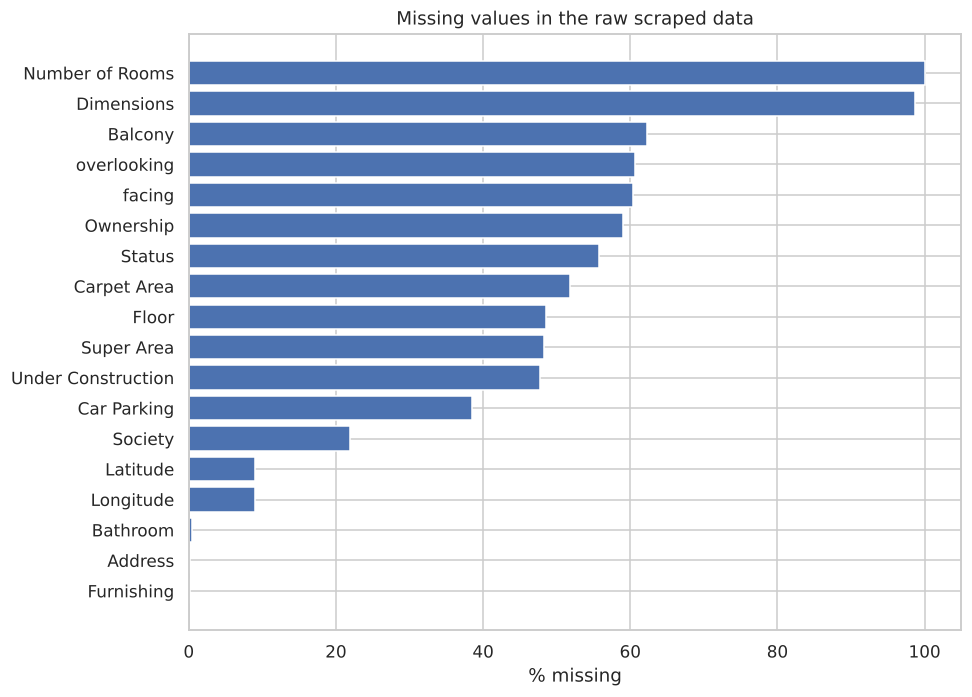

In [4]:
fig, ax = plt.subplots(figsize=(9, 6.5))
m = missing[missing > 0]
ax.barh(m.index, m.values, color='#4C72B0'); ax.invert_yaxis()
ax.set_xlabel('% missing'); ax.set_title('Missing values in the raw scraped data')
save(fig, 're_01_missing_values')

## 2. Drop unwanted columns

* `Name` repeats `Title`
* `Number of Rooms` and `Dimensions` are almost completely empty
* `Under Construction` repeats the information in `Status`

In [5]:
housing = housing.drop(columns=['Name', 'Number of Rooms', 'Dimensions', 'Under Construction'])
housing['Status'] = housing['Status'].fillna('Under Construction')
housing['Status'].value_counts()

Status
Under Construction    1668
Ready to Move         1321
Name: count, dtype: int64

## 3. Extract numbers from text

### 3.1 Bedrooms and property type from `Title`
Titles look like `"3 BHK Flat for Sale ..."` or `"Studio Apartment for Sale ..."`. A studio is treated as 1 bedroom. The single `"> 10 BHK House"` listing can't be given a number, so it is dropped later.

In [6]:
title = housing['Title'].str.strip()
housing['Bedrooms'] = pd.to_numeric(title.str.extract(r'^(\d+)\s*BHK', expand=False))
housing.loc[title.str.startswith('Studio'), 'Bedrooms'] = 1

ptype = title.str.extract(r'^(?:\d+\s*BHK\s+|Studio\s+)?(.*?)\s+for Sale', expand=False)
housing['Property Type'] = ptype.replace({'Apartment': 'Studio Apartment'})
housing.loc[title.str.startswith('Studio'), 'Property Type'] = 'Studio Apartment'
housing[['Title', 'Bedrooms', 'Property Type']].head()

,Title,Bedrooms,Property Type
0,"4 BHK Flat for Sale Luxury Floors, in DLF City...",4.0,Flat
1,"3 BHK Flat for Sale Eldeco Acclaim, in Sohna",3.0,Flat
2,"2 BHK Flat for Sale The Leaf, in Sector 85",2.0,Flat
3,"Studio Apartment for Sale M3M Corner Walk, in...",1.0,Studio Apartment
4,"2 BHK Flat for Sale M3M Soulitude, in Sector 89",2.0,Flat


In [7]:
housing['Property Type'].value_counts()

Property Type
Flat                2698
Villa                164
Studio Apartment      63
House                 63
> 10 BHK House         1
Name: count, dtype: int64

### 3.2 Price in rupees
Prices look like `₹92.8 Lac` or `₹1.18 Cr`. 1 Lac = 1,00,000 and 1 Cr = 1,00,00,000. "Call for Price" listings have no price and become NaN.

In [8]:
def parse_price(text):
    m = pd.Series(text).astype(str).str.extract(r'₹\s*([\d.]+)\s*(Lac|Cr)')
    value = pd.to_numeric(m[0])
    return np.where(m[1] == 'Cr', value * 1e7, value * 1e5)

housing['Price'] = parse_price(housing['Price'])
housing['Price'].describe()

count    2.985000e+03
mean     6.001546e+07
std      1.165611e+09
min      1.000000e+05
25%      4.570000e+06
50%      6.950000e+06
75%      1.200000e+07
max      4.118000e+10
Name: Price, dtype: float64

### 3.3 Area in square feet
`Super Area` is used where it exists, with `Carpet Area` as the fallback. Units are converted to sqft:
* 1 sq yard = 9 sqft
* 1 sq metre = 10.764 sqft

In [9]:
area_text = housing['Super Area'].fillna(housing['Carpet Area']).astype(str)
parts = area_text.str.extract(r'([\d.]+)\s*(sqft|sqyrd|sqm)')
factor = parts[1].map({'sqft': 1, 'sqyrd': 9, 'sqm': 10.764})
housing['Area(sqft)'] = pd.to_numeric(parts[0]) * factor
print(parts[1].value_counts(dropna=False))
housing['Area(sqft)'].describe()

1
sqft     2916
sqyrd      50
sqm        18
NaN         5
Name: count, dtype: int64


count     2984.000000
mean      1319.898984
std       1235.840550
min        173.000000
25%        737.000000
50%       1120.000000
75%       1600.000000
max      50000.000000
Name: Area(sqft), dtype: float64

## 4. Fix data errors

### 4.1 Invalid bathroom values

In [10]:
print(housing['Bathroom'].value_counts(dropna=False))
housing['Bathroom'] = pd.to_numeric(housing['Bathroom'], errors='coerce')  # '> 10' -> NaN

Bathroom
2       1560
3        844
4        236
1        224
5         80
6         23
NaN       15
7          6
> 10       1
Name: count, dtype: int64


### 4.2 Latitude and longitude are swapped
India lies between roughly **6–37° N latitude** and **68–98° E longitude**. In the raw data, the `Latitude` column holds values around 72–88, which are longitudes. The scraper stored the two fields the wrong way round, so we swap them back and check the result.

In [11]:
print('Before:', housing[['Latitude', 'Longitude']].describe().loc[['min', 'max']].round(2).to_dict())
housing[['Latitude', 'Longitude']] = housing[['Longitude', 'Latitude']].values
ok = housing['Latitude'].between(6, 37) & housing['Longitude'].between(68, 98)
print('Rows with valid India coordinates:', ok.sum(), 'of', housing['Latitude'].notna().sum())

Before: {'Latitude': {'min': 26.89, 'max': 91.82}, 'Longitude': {'min': 8.49, 'max': 30.71}}
Rows with valid India coordinates: 2719 of 2721


## 5. Feature engineering

### 5.1 Parking spaces and furnishing

In [12]:
# '2 Covered, 1 Open' -> 3 spaces; missing -> 0 (not specified)
housing['Parking'] = (housing['Car Parking'].fillna('').astype(str).str.findall(r'(\d+)')
                      .apply(lambda xs: sum(int(x) for x in xs)))
# A few listings give the whole society's parking (e.g. '835 Covered'), not the flat's.
print('Listings with more than 10 parking spaces (society totals):', (housing['Parking'] > 10).sum())
housing.loc[housing['Parking'] > 10, 'Parking'] = 0
housing['Furnishing'] = housing['Furnishing'].fillna('Unfurnished')
housing['Parking'].value_counts().sort_index().head(8)

Listings with more than 10 parking spaces (society totals): 8


Parking
0    1160
1    1551
2     223
3      33
4      11
5       3
6       4
7       2
Name: count, dtype: int64

### 5.2 State for each city

In [13]:
state_map = {
    'Kerala': ['Kochi', 'Trivandrum', 'Thrissur'],
    'Maharashtra': ['Aurangabad', 'Nashik', 'Mumbai', 'Navi-Mumbai', 'Pune', 'Bhiwandi', 'Thane', 'Nagpur'],
    'Gujarat': ['Ahmedabad', 'Surat', 'Vadodara', 'Gandhinagar', 'Vapi'],
    'Karnataka': ['Mangalore', 'Bangalore', 'Mysore'],
    'Uttar Pradesh': ['Meerut', 'Agra', 'Allahabad', 'Kanpur', 'Varanasi', 'Vrindavan', 'Noida', 'Greater-Noida',
                      'Ghaziabad', 'Lucknow'],
    'Telangana': ['Hyderabad'],
    'Haryana': ['Gurgaon', 'Faridabad', 'Sonipat'],
    'Tamil Nadu': ['Chennai', 'Coimbatore', 'Trichy'],
    'West Bengal': ['Durgapur', 'Kolkata'],
    'Rajasthan': ['Jodhpur', 'Jaipur', 'Udaipur'],
    'Madhya Pradesh': ['Bhopal', 'Indore'],
    'Odisha': ['Bhubaneswar'],
    'Andhra Pradesh': ['Tirupati', 'Vijayawada', 'Visakhapatnam', 'Guntur'],
    'Assam': ['Guwahati'],
    'Jharkhand': ['Bokaro-Steel-City', 'Ranchi', 'Jamshedpur'],
    'Uttarakhand': ['Haridwar', 'Dehradun'],
    'Chhattisgarh': ['Raipur'],
    'Bihar': ['Patna'],
    'Delhi': ['New-Delhi'],
    'Goa': ['Goa'],
    'Chandigarh': ['Chandigarh'],
}
city_to_state = {city: state for state, cities in state_map.items() for city in cities}
housing['State/Territory'] = housing['City'].map(city_to_state)
assert housing['State/Territory'].notna().all(), housing.loc[housing['State/Territory'].isna(), 'City'].unique()
housing['State/Territory'].value_counts().head(10)

State/Territory
Maharashtra      873
Uttar Pradesh    482
Karnataka        253
Gujarat          253
Haryana          196
Tamil Nadu       158
Telangana        150
Rajasthan        109
West Bengal       99
Kerala            62
Name: count, dtype: int64

### 5.3 City tier
Cities are grouped into tiers based on India's HRA city classification:
* **Tier 1:** X-class metros
* **Tier 2:** Y-class cities
* **Tier 3 and Tier 4:** smaller Z-class cities

The original code had cities appearing in two lists and silently labelled any unmatched city as Tier 1. Each city now has exactly one tier, and an assert catches any city that's missing.

In [14]:
tiers = {
    'Tier1': ['Kolkata', 'Chennai', 'Hyderabad', 'Bangalore', 'Navi-Mumbai', 'Mumbai', 'New-Delhi'],
    'Tier2': ['Ahmedabad', 'Greater-Noida', 'Goa', 'Jamshedpur', 'Bokaro-Steel-City', 'Indore', 'Guntur', 'Thrissur',
              'Allahabad', 'Jaipur', 'Patna', 'Gandhinagar', 'Bhopal', 'Pune', 'Lucknow', 'Gurgaon', 'Ranchi', 'Thane',
              'Aurangabad', 'Kochi', 'Nagpur', 'Mangalore', 'Faridabad', 'Durgapur', 'Kanpur', 'Dehradun', 'Varanasi',
              'Noida', 'Surat', 'Raipur', 'Tirupati', 'Chandigarh', 'Trichy', 'Vadodara', 'Nashik', 'Mysore',
              'Ghaziabad', 'Visakhapatnam', 'Bhiwandi', 'Meerut'],
    'Tier3': ['Coimbatore', 'Haridwar', 'Agra', 'Udaipur', 'Vijayawada', 'Sonipat'],
    'Tier4': ['Vrindavan', 'Guwahati', 'Bhubaneswar', 'Trivandrum', 'Vapi', 'Jodhpur'],
}
city_to_tier = {city: tier for tier, cities in tiers.items() for city in cities}
housing['Tier'] = housing['City'].map(city_to_tier)
assert housing['Tier'].notna().all(), housing.loc[housing['Tier'].isna(), 'City'].unique()
housing['Tier'].value_counts()

Tier
Tier2    1858
Tier1     914
Tier4     121
Tier3      96
Name: count, dtype: int64

## 6. Remove duplicates and invalid rows

In [15]:
n0 = len(housing)
housing = housing.drop_duplicates(subset='Property Id')
print(f'Duplicate listings removed: {n0 - len(housing)}')

housing = housing.dropna(subset=['Price', 'Area(sqft)', 'Bathroom', 'Bedrooms'])
print('After dropping rows missing price/area/bathroom/bedrooms:', len(housing))

Duplicate listings removed: 932
After dropping rows missing price/area/bathroom/bedrooms: 2039


In [16]:
housing['Price per sqft'] = housing['Price'] / housing['Area(sqft)']
housing['Price per sqft'].describe().round(0)

count        2039.0
mean        22797.0
std        443204.0
min            56.0
25%          4503.0
50%          6400.0
75%         10126.0
max      17194154.0
Name: Price per sqft, dtype: float64

Some listings are clearly data-entry errors, such as a 1-sqft flat or a price of ₹50/sqft. We keep only plausible values:
* Area: 150–15,000 sqft
* Price per sqft: ₹1,000–₹1,00,000

In [17]:
valid = housing['Area(sqft)'].between(150, 15000) & housing['Price per sqft'].between(1000, 100000)
print('Implausible rows removed:', (~valid).sum())
print(housing.loc[~valid, ['Title', 'Price', 'Area(sqft)', 'Price per sqft']].head())
housing = housing[valid].copy()

Implausible rows removed: 6
                                                  Title         Price  \
236                  2 BHK Flat for Sale in Sector 117   3.400000e+06   
834       2 BHK Flat for Sale Lodha The Park, in Worli   1.200000e+05   
1545                  5 BHK Villa for Sale in Perungudi  3.900000e+07   
2483  2 BHK House for Sale in Gruham Garden Valley, ...  1.000000e+05   
2512  4 BHK Flat for Sale Viaana, in Vijayanagar 4th...  4.118000e+10   

      Area(sqft)  Price per sqft  
236       5994.0    5.672339e+02  
834        890.0    1.348315e+02  
1545     50000.0    7.800000e+02  
2483      1800.0    5.555556e+01  
2512      2395.0    1.719415e+07  


Some listings are far from their own city's typical price, such as a 2 BHK in Trivandrum at ₹60,000/sqft or a 1 BHK in Gurgaon at ₹45,000/sqft. These are usually typos (₹95 Lac entered as ₹9.5 Cr) or mislabelled properties.

Like the original `remove_pps_outliers` step, we drop listings whose price per sqft is **more than 3× or less than ⅓ of their city's median**. This only applies to cities with at least 5 listings.

In [18]:
city_median = housing.groupby('City')['Price per sqft'].transform('median')
city_count = housing.groupby('City')['City'].transform('size')
ratio = housing['Price per sqft'] / city_median
city_outlier = (city_count >= 5) & ((ratio > 3) | (ratio < 1 / 3))
print(f'City-level price outliers removed: {city_outlier.sum()} ({city_outlier.mean():.1%})')
housing = housing[~city_outlier].copy()

City-level price outliers removed: 29 (1.4%)


## 7. Final column order and save

In [19]:
cols = ['Property Id', 'Society Name', 'Property Type', 'Bedrooms', 'Bathroom', 'Area(sqft)', 'Parking',
        'Address', 'City', 'Tier', 'State/Territory', 'Latitude', 'Longitude', 'Transaction', 'Furnishing',
        'Status', 'Description', 'URL', 'Price per sqft', 'Price']
housing = housing[cols].reset_index(drop=True)
housing[['Bedrooms', 'Bathroom', 'Parking']] = housing[['Bedrooms', 'Bathroom', 'Parking']].astype(int)
housing['Price per sqft'] = housing['Price per sqft'].round(0).astype(int)
housing.info()

<class 'pandas.DataFrame'>
RangeIndex: 2004 entries, 0 to 2003
Data columns (total 20 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Property Id      2004 non-null   str    
 1   Society Name     2004 non-null   str    
 2   Property Type    2004 non-null   str    
 3   Bedrooms         2004 non-null   int64  
 4   Bathroom         2004 non-null   int64  
 5   Area(sqft)       2004 non-null   float64
 6   Parking          2004 non-null   int64  
 7   Address          1999 non-null   str    
 8   City             2004 non-null   str    
 9   Tier             2004 non-null   str    
 10  State/Territory  2004 non-null   str    
 11  Latitude         1833 non-null   float64
 12  Longitude        1833 non-null   float64
 13  Transaction      2004 non-null   str    
 14  Furnishing       2004 non-null   str    
 15  Status           2004 non-null   str    
 16  Description      2004 non-null   str    
 17  URL              2004 non

In [20]:
out = ROOT / 'data/processed/magicbricks_cleaned.csv'
housing.to_csv(out, index=False)
print(f'Saved {len(housing)} clean listings ({len(housing) / 2989:.0%} of raw) to {out}')

Saved 2004 clean listings (67% of raw) to ../data/processed/magicbricks_cleaned.csv
